In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize
from itertools import product
import pandas as pd

In [2]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x >= value), None)

def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    cs_quad = gradient(P[:-1],e_quad)
    return n_quad, e_quad, cs_quad

@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

from itertools import product
import numpy as np
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

def find_valid_parameters(delta_P_arr, y_intersect, x_intersect, p_total, mu_total):
    A, B = [], []
    mu_c_h_arr, mu_c_q_arr = [], []
    P_c_h_arr, P_c_q_arr = [], []
    delta_P_found = []

    index = find_first_larger_index(p_total, y_intersect)
    #print(index)
    x1 = np.array(mu_total[:index])
    y1 = np.array(p_total[:index])

    x2 = np.array(mu_total[index:])
    y2 = np.array(p_total[index:])

    P_h_int_func = interpolate.interp1d(x1, y1, fill_value="extrapolate")
    P_q_int_func = interpolate.interp1d(x2, y2, fill_value="extrapolate")

    mu_start = mu_total[0]
    mu_end = mu_total[-1]

    mu_new = np.linspace(mu_start, mu_end, 2000)
    P_had_array = P_h_int_func(mu_new)
    P_quark_array = P_q_int_func(mu_new)
    #plt.plot(x1,y1)
    #plt.plot(x2,y2)
    #plt.show()
    #plt.plot(mu_new,P_had_array)
    #plt.plot(mu_new,P_quark_array)
    #plt.show()
    y_diff = np.abs(P_had_array - P_quark_array)

    for delta_P in delta_P_arr:
        found = False

        # Iterate through all combinations of mu_c_h and mu_c_q
        for mu_c_h, mu_c_q in product(mu_new, repeat=2):
            if found:
                break

            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            # Check if alpha is positive
            if alp <= 0:
                continue

            # Calculate the mixed phase pressure
            P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)

            # Split the pressure difference calculation
            min_idx = np.argmin(y_diff)
            m_h_P_diff = P_m[:min_idx] - P_had_array[:min_idx]
            m_q_P_diff = P_m[min_idx:] - P_quark_array[min_idx:]

            # Validate the pressure conditions
            if np.all(m_h_P_diff >= 0) and np.all(m_q_P_diff >= 0):
                #print(np.min(m_h_P_diff), np.min(m_q_P_diff))
                delta_P_found.append(delta_P)
                A.append(alp)
                B.append(bet)
                mu_c_h_arr.append(mu_c_h)
                mu_c_q_arr.append(mu_c_q)
                P_c_h_arr.append(P_h)
                P_c_q_arr.append(P_q)
                found = True

    print(f"Found {len(A)} valid sets of parameters.")
    return A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found

In [3]:
def mixed_phase(mu_total, p_total,n_total, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, P_crit, delta_P_arr):
    P_arr_dp = []
    E_arr_dp = []
    number_density_dp = []
    mu_arr_dp = []
    #print(A)
    #print(B)
    #print(mu_c_h_arr)
    print(mu_c_q_arr)
    #print(P_c_h_arr)
    #print(P_c_q_arr)
    #print(mu_crit)
    #print(P_crit)
    #print(delta_P_arr)
    
    for i in range(len(A)):
        index_1 = find_first_larger_index(mu_total, mu_c_h_arr[i])
        index_2 = find_first_larger_index(mu_total, mu_c_q_arr[i])

        print(mu_total[index_1])
        print(mu_total[index_2])
        
        mu_mixed = np.linspace(mu_total[index_1], mu_total[index_2], len(mu_total[index_1:index_2]))

        P_m = quad_P(mu_crit, mu_mixed, A[i], B[i], delta_P_arr[i], P_crit)
        P_had_half = p_total[:index_1]
        P_quark_half = p_total[index_2:]

        grad_had = n_total[:index_1]
        grad_m = gradient(P_m,mu_mixed)
        grad_quark = n_total[index_2:]

        #print(mu_total)
        #print(mu_mixed)

        mu_arr = np.concatenate((mu_total[:index_1], mu_mixed[:][:][:-1], mu_total[index_2:]))

        grad_dummy = np.concatenate((grad_had,grad_m,grad_quark))
        P_arr_dummy = np.concatenate((P_had_half,P_m[:-1],P_quark_half))

        e_dummy = (grad_dummy*mu_arr)-P_arr_dummy

        P_arr_dp.append(P_arr_dummy)
        E_arr_dp.append(e_dummy)
        number_density_dp.append(grad_dummy)
        mu_arr_dp.append(mu_arr)

    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [128]:
def smoothness_eos(pressure, mu, number_density, p_crit, mu_crit):
    delta_P_arr = [0.03, 0.0325, 0.035, 0.0375, 0.04, 0.0425, 0.045, 0.0475, 0.05]
    #delta_P_arr = [0.02, 0.04, 0.05]
    delta_P_arr = [0.04]
    
    A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = find_valid_parameters(delta_P_arr, p_crit, mu_crit, pressure, mu)
    P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = mixed_phase(mu, pressure, number_density, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, p_crit, delta_P_found)
    
    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [5]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [6]:
g_quark = 3
n_quark = np.linspace(0.5344,2.3,1000)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

In [7]:
# Hadronic EOS
p_had = P_from_nb(n_had, K_had, Gam_had)
mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)
e_had = e_from_n(n_had, K_had, Gam_had, m0_had)
cs_had = np.gradient(p_had, e_had)

K_quark = p_had[-1] / (n_quark[0] ** g_quark)
e_mid = n_quark[0]*mu_had[-1] - p_had[-1]
m0_quark = (e_mid - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

# Quark EOS
p_quark = P_from_nb(n_quark, K_quark, g_quark)
mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)
cs_quark = np.gradient(p_quark, e_quark)

# Concatenate hadronic and quark data
e_combined = np.concatenate((e_had, e_quark))
p_combined = np.concatenate((p_had, p_quark))
mu_combined = np.concatenate((mu_had, mu_quark))
cs_combined = np.concatenate((cs_had, cs_quark))
n_combined = np.concatenate((n_had, n_quark))

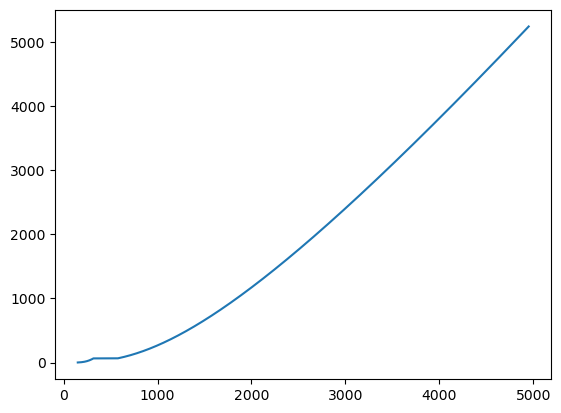

In [8]:
plt.plot(e_combined, p_combined)

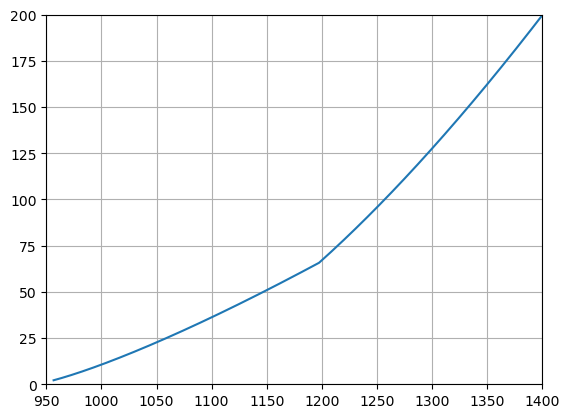

In [9]:
plt.plot(mu_combined, p_combined)
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.grid()
plt.show()

In [10]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = smoothness_eos(pressure=p_combined, mu=mu_combined, number_density=n_combined, p_crit=p_had[-1], mu_crit=mu_had[-1])

Found 3 valid sets of parameters.
[1224.255822933124, 1252.0660351904723, 1267.709279585231]
1173.9578041850107
1225.2373478192476
1153.0128291443891
1252.2327546313186
1144.3553212978288
1267.7684940816878


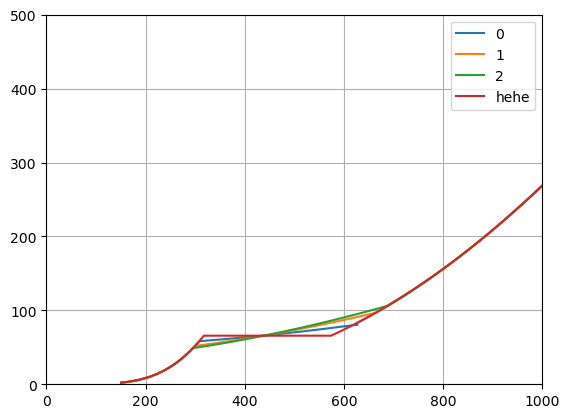

In [11]:
for i in range(len(P_arr_dp)):
    plt.plot(E_arr_dp[i], P_arr_dp[i], label=i)
plt.plot(e_combined, p_combined, label = 'hehe')
plt.xlim(0,1000)
plt.ylim(0,500)
plt.legend()
plt.grid()
plt.show() 

In [12]:
P_crit_1 = p_had[-1]*(1+0.01)
P_crit_2 = p_had[-1]*(1+0.3)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

In [13]:
b_optimal = []
a_optimal = []
P_optimal = []
min_distance_points = []
min_distances = []

for P in P_crit_new:
    # Define your points
    x1, y1 = mu_combined[0], p_combined[0]  # First point the curve must pass through
    x2, y2 = mu_had[-1], P  # Critical point

    # For inequality constraint defining hadronic part.
    x_values = np.array(mu_combined[1:])  # Hadronic part x_values
    f_values = np.array(p_combined[1:])   # Corresponding y_values

    # Define the quadratic function
    def quadratic(x, a, b):
        return a * (x - x2)**2 + b * (x - x2) + y2

    # Objective function: sum of squared differences (least distance point)
    def objective(params):
        a, b = params
        return 0

    # Initial guess for parameters
    initial_guess = [0, 0]

    # Constraint: quadratic must pass through the first point (x1, y1)
    def eq_constraint(params):
        a, b = params
        return quadratic(x1, a, b) - y1

    # Inequality constraint: ensure quadratic stays above hadronic part
    def ineq_constraint(params):
        a, b = params
        return quadratic(x_values, a, b) - f_values

    # Define the constraints
    constraints = [
        {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
        {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
    ]

    # Perform the optimization
    result = minimize(objective, initial_guess, constraints=constraints)

    if result.success:
        a_opt, b_opt = result.x

        # Find the least distance point
        min_distance = float('inf')
        closest_point = None

        # Calculate the quadratic value and find minimum distance
        for x, f in zip(x_values, f_values):
            y_quad = quadratic(x, a_opt, b_opt)
            distance = np.abs(y_quad - f)  # Only y-direction distance
            if distance < min_distance:
                min_distance = distance
                closest_point = (x, y_quad)

        # Save the optimal solution
        a_optimal.append(a_opt)
        b_optimal.append(b_opt)
        P_optimal.append(P)
        min_distance_points.append(closest_point)
        min_distances.append(min_distance)

    else:
        continue
# Convert min_distances to a NumPy array
min_distances = np.array(min_distances)

In [35]:
def concatenate_eos(P_max_points_1,mu_crit,P_all_1,p_total,mu_total,a_optimal_1,b_optimal_1,e_total,n_total):
    eos_final = []
    x2, y2 = mu_crit, P_all_1[0]  # Critical point
    a_op = a_optimal_1[0]
    b_op = b_optimal_1[0]        
    # Define quadratic function
    def quadratic(x):
        return a_op * (x - x2)**2 + b_op * (x - x2) + y2
    
    # Generate smooth quadratic fit until quark EOS
    index = find_first_larger_index(mu_total, P_max_points_1[0][0])
    print(mu_total)
    print(index)
    mu_mixed = np.linspace(mu_total[0], mu_total[index], len(mu_total[:index]))
    p_fit = quadratic(mu_mixed)
    n_mix,e_mix,cs_mix = compute_n_e(p_fit, mu_mixed)
    
    e_t = np.concatenate((e_mix, e_total[index:]))
    #cs_t = np.concatenate((cs_mix, cs_total[i][index:]))
    p_t = np.concatenate((p_fit, p_total[index:]))
    mu_t = np.concatenate((mu_mixed, mu_total[index:]))

    #n_mix,e_t,cs_t = compute_n_e(p_t, mu_t)
    eos_final.append((p_t, mu_t, e_t))
    #print(index)
    #print(mu_mixed)
    #print(mu_total[i][index:])
    return eos_final

In [15]:
eos = concatenate_eos(min_distance_points,mu_had[-1],P_optimal,p_combined,mu_combined,a_optimal,b_optimal,e_combined,n_combined)

[ 956.58252996  956.64943985  956.71654547 ... 4420.62238412 4425.86963561
 4431.12092386]
1197


In [16]:
eos

[(array([2.17013897e+00, 2.24870878e+00, 2.32755847e+00, ...,
         5.21718780e+03, 5.22924257e+03, 5.24131589e+03]),
  array([ 956.58252996,  957.05043383,  957.51833771, ..., 4420.62238412,
         4425.86963561, 4431.12092386]),
  array([ 158.45795591,  159.03042732,  159.60317862, ..., 4934.61795404,
         4942.4354541 , 4950.26223155]))]

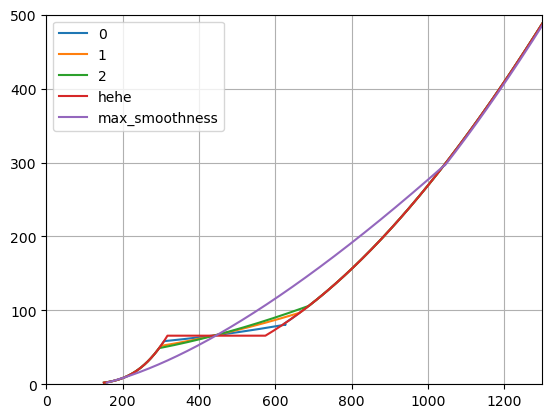

In [17]:
for i in range(len(P_arr_dp)):
    plt.plot(E_arr_dp[i], P_arr_dp[i], label=i)
plt.plot(e_combined, p_combined, label = 'hehe')
plt.plot(eos[0][2], eos[0][0][:-1], label = "max_smoothness")
plt.xlim(0,1300)
plt.ylim(0,500)
plt.legend()
plt.grid()
plt.show() 

In [18]:
from TOV_Solver import generate_mr_curve

In [19]:
r,m,_,_ = generate_mr_curve(eos[0][2], eos[0][0][:-1])

In [20]:
rr,mm,_,_ = generate_mr_curve(e_combined, p_combined)

In [21]:
for i in range(len(P_arr_dp)):
    r3, m3, _, _ = generate_mr_curve(E_arr_dp[i], P_arr_dp[i])
    globals()[f"r{i}"] = r3
    globals()[f"m{i}"] = m3

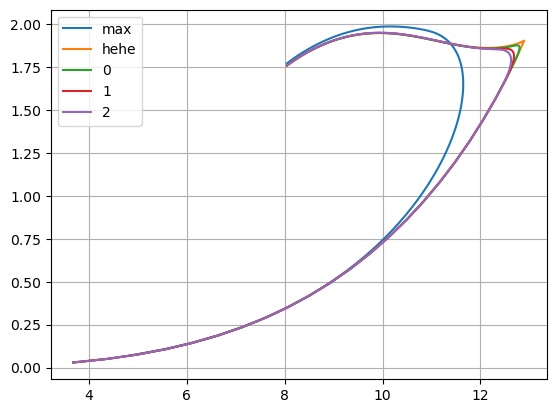

In [22]:
plt.plot(r,m, label = 'max')
plt.plot(rr,mm, label = 'hehe')
for i in range(3):
    plt.plot(globals()[f"r{i}"], globals()[f"m{i}"], label = i)
plt.grid()
#plt.xlim(8,12)
#plt.ylim(1.90,2)
plt.legend()
plt.show()

In [9]:
df = pd.read_csv('vMIT_p_mu_extended1.dat', delim_whitespace=True, usecols=[0, 1])
df_1 = pd.read_csv('ZLA_p_mu_extended1.dat', delim_whitespace=True, usecols=[0, 1])

/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_2881/4082693411.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('vMIT_p_mu_extended1.dat', delim_whitespace=True, usecols=[0, 1])
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_2881/4082693411.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_1 = pd.read_csv('ZLA_p_mu_extended1.dat', delim_whitespace=True, usecols=[0, 1])


In [74]:
# Get first and second columns (column index 0 and 1)
cols_pressure_q = df.iloc[:,0]  # This returns a DataFrame with just those two columns
cols_energy_q = df.iloc[:,1]

cols_pressure_had = df_1.iloc[:,0]
cols_energy_had = df_1.iloc[:,1]

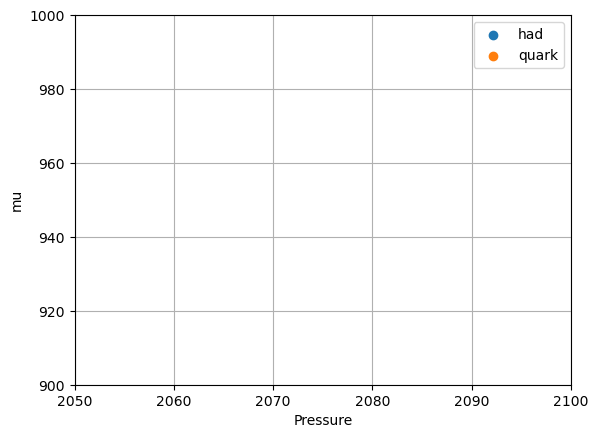

In [11]:
plt.scatter(cols_energy_had, cols_pressure_had, label = 'had')
plt.scatter(cols_energy_q, cols_pressure_q, label = 'quark')
plt.xlim(2050, 2100)
plt.ylim(900, 1000)
plt.legend()
plt.grid()
plt.xlabel('Pressure')
plt.ylabel('mu')
plt.show()

In [92]:
for i in range(len(cols_energy_had)):
    if cols_energy_had[i] > 2080:
        print(i)
        print(cols_energy_had[i])
        break

46
2080.6888452726066


In [13]:
for i in range(len(cols_energy_q)):
    if cols_energy_q[i] > 2060:
        print(i)
        print(cols_energy_q[i])
        break

61
2074.761332782803


In [14]:
cols_mu_had = np.array(cols_energy_had[:46])
cols_mu_q  = np.array(cols_energy_q[60:])

cols_p_had = np.array(cols_pressure_had[:46])
cols_p_q  = np.array(cols_pressure_q[60:])

In [77]:
len(cols_mu_had)

46

In [80]:
from scipy.interpolate import interp1d

In [97]:
len(cols_energy_had)


196

In [106]:
cols_mu_new_had = np.linspace(cols_energy_had[0], cols_energy_had[195], 3000)
f_quadratic = interp1d(cols_energy_had, cols_pressure_had, kind='quadratic')

cols_p_had_new = f_quadratic(cols_mu_new_had)

In [113]:
cols_mu_had = cols_mu_new_had
cols_p_had = cols_p_had_new

In [108]:
for i in range(len(cols_mu_had)):
    if cols_mu_had[i] > 2050:
        print(i)
        print(cols_mu_had[i])
        break

282
2053.9102496298765


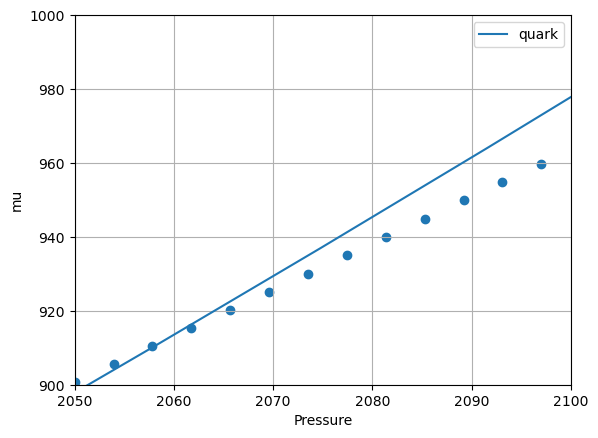

In [109]:
plt.scatter(cols_mu_had, cols_p_had)
plt.plot(cols_energy_q, cols_pressure_q, label = 'quark')
plt.xlim(2050, 2100)
plt.ylim(900, 1000)
plt.legend()
plt.grid()
plt.xlabel('Pressure')
plt.ylabel('mu')
plt.show()

In [121]:
cols_mu = np.concatenate((cols_mu_had[:284], cols_energy_q[60:]))
cols_p = np.concatenate((cols_p_had[:284], cols_pressure_q[60:]))

In [122]:
cols_n_had, cols_n_q = np.gradient(cols_p_had, cols_mu_had), np.gradient(cols_pressure_q, cols_energy_q)
cols_n = np.concatenate((cols_n_had[:284], cols_n_q[60:]))

cols_e = (cols_n*cols_mu) - cols_p

In [123]:
cols_p_had[284]

915.3013189947109

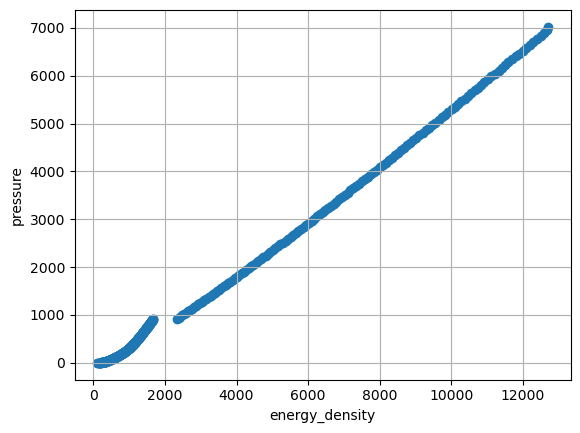

In [124]:
plt.scatter(cols_e, cols_p)
plt.xlabel('energy_density')
plt.ylabel('pressure')
plt.grid()
plt.show()

In [125]:
cols_p_had[-1]

36508.5

In [126]:
cols_p = cols_p.tolist()
cols_mu = cols_mu.tolist()
cols_n = cols_n.tolist()


In [127]:
cols_mu_q

array([2057.95382307, 2074.76133278, 2091.47766111, 2108.13167357,
       2124.69097467, 2141.18235294, 2157.61745239, 2173.95203253,
       2190.24294119, 2206.44004574, 2222.58774331, 2238.66415449,
       2254.68527819, 2270.63497068, 2286.52914761, 2302.35688512,
       2318.13887219, 2333.84880925, 2349.51724138, 2365.12956242,
       2380.68119014, 2396.18735608, 2411.63196562, 2427.03484598,
       2442.38444584, 2457.69107076, 2472.93872141, 2488.15564588,
       2503.31238917, 2518.43688156, 2533.50438187, 2548.54237288,
       2563.53704651, 2578.4749271 , 2593.38710671, 2608.24930734,
       2623.07995432, 2637.85918139, 2652.61320335, 2667.31822651,
       2681.99624487, 2696.62758001, 2711.23395839, 2725.79579828,
       2740.33085502, 2754.8298949 , 2769.29111162, 2783.72467147,
       2798.11501895, 2812.48668759, 2826.81340178, 2841.11950734,
       2855.38595545, 2869.63329975, 2883.83579326, 2898.02406685,
       2912.16915669, 2926.3013245 , 2940.39824258, 2954.46093

In [129]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = smoothness_eos(pressure = cols_p, mu = cols_mu, number_density = cols_n, p_crit = cols_p_q[0], mu_crit = cols_mu_q[0])

Found 0 valid sets of parameters.
[]


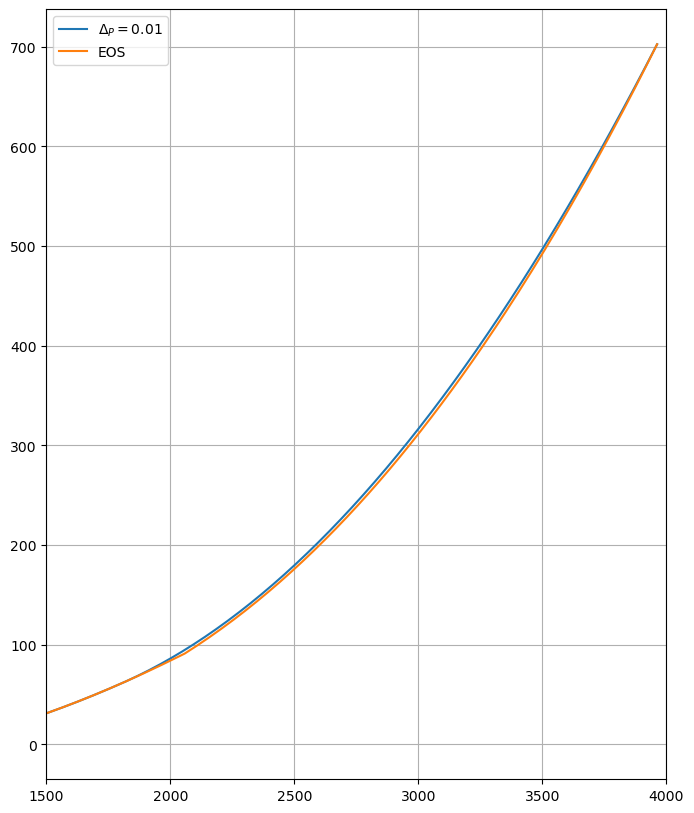

In [73]:
plt.figure(figsize=(8, 10))
for i in range(len(P_arr_dp)):
    plt.plot(mu_arr_dp[i], P_arr_dp[i], label=rf'$\Delta_{{P}} = {(i+1)*0.01:.2f}$')
plt.plot(cols_mu, cols_p, label = 'EOS')
#plt.plot(eos[0][2], eos[0][0][:-1], label = "max_smoothness")
plt.xlim(1500,4000)
#plt.ylim(70,130)
plt.legend()
plt.grid()
plt.show() 

In [30]:
P_crit_1 = cols_p_had[-1]*(1+0.01)
P_crit_2 = cols_p_had[-1]*(1+0.3)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

In [31]:
b_optimal = []
a_optimal = []
P_optimal = []
min_distance_points = []
min_distances = []

for P in P_crit_new:
    # Define your points
    x1, y1 = cols_mu[0], cols_p[0]  # First point the curve must pass through
    x2, y2 = cols_mu_had[-1], P  # Critical point

    # For inequality constraint defining hadronic part.
    x_values = np.array(cols_mu[1:])  # Hadronic part x_values
    f_values = np.array(cols_p[1:])   # Corresponding y_values

    # Define the quadratic function
    def quadratic(x, a, b):
        return a * (x - x2)**2 + b * (x - x2) + y2

    # Objective function: sum of squared differences (least distance point)
    def objective(params):
        a, b = params
        return 0

    # Initial guess for parameters
    initial_guess = [0, 0]

    # Constraint: quadratic must pass through the first point (x1, y1)
    def eq_constraint(params):
        a, b = params
        return quadratic(x1, a, b) - y1

    # Inequality constraint: ensure quadratic stays above hadronic part
    def ineq_constraint(params):
        a, b = params
        return quadratic(x_values, a, b) - f_values

    # Define the constraints
    constraints = [
        {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
        {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
    ]

    # Perform the optimization
    result = minimize(objective, initial_guess, constraints=constraints)

    if result.success:
        a_opt, b_opt = result.x

        # Find the least distance point
        min_distance = float('inf')
        closest_point = None

        # Calculate the quadratic value and find minimum distance
        for x, f in zip(x_values, f_values):
            y_quad = quadratic(x, a_opt, b_opt)
            distance = np.abs(y_quad - f)  # Only y-direction distance
            if distance < min_distance:
                min_distance = distance
                closest_point = (x, y_quad)

        # Save the optimal solution
        a_optimal.append(a_opt)
        b_optimal.append(b_opt)
        P_optimal.append(P)
        min_distance_points.append(closest_point)
        min_distances.append(min_distance)

    else:
        continue
# Convert min_distances to a NumPy array
min_distances = np.array(min_distances)

In [32]:
b_optimal

[0.17437083774811202,
 0.17438102813066853,
 0.17439121826200166,
 0.1744014086445435,
 0.1744115990270853,
 0.17442178966089444,
 0.174431979792169,
 0.17444217017471084,
 0.1744523605572526,
 0.17446255093979438,
 0.1744727415736768,
 0.17448293170487808,
 0.17449312208741985,
 0.17450331246996165,
 0.1745135028525035,
 0.17452369348635757,
 0.17453388361758723,
 0.174544074000129,
 0.1745542643826708,
 0.17456445476521262,
 0.17457464539914,
 0.17458483553029622,
 0.1745950259128381,
 0.17460521629537987,
 0.17461540667792178,
 0.17462559731192243,
 0.17463578744300548,
 0.17464597782554728,
 0.17465616820808905,
 0.17466635859063093,
 0.17467654922470496,
 0.17468673935571455,
 0.1746969297382563,
 0.17470712012079814,
 0.1747173107550323,
 0.1747275011374875,
 0.17473769126842364,
 0.1747478816509654,
 0.17475807228525825,
 0.17476826266781467,
 0.17477845305026993,
 0.17478864318113263,
 0.1747988335636746,
 0.17480902419804062,
 0.1748192145805971,
 0.1748294049630524,
 0.174839

In [33]:
cols_mu

[948.48792,
 949.2840978130813,
 951.0694261131897,
 954.3271556985909,
 959.0341696472173,
 965.5164676158557,
 973.9637582300256,
 984.4519350701823,
 997.0030465036333,
 1011.6080470584856,
 1028.2277864444488,
 1046.7583550759196,
 1067.0783807791547,
 1089.000789473684,
 1112.3095329131568,
 1136.7630911230845,
 1162.0941611824076,
 1188.054525291877,
 1214.4171797294655,
 1240.9920572300248,
 1267.647733874612,
 1294.2938925733652,
 1320.8992508981662,
 1347.4787251161952,
 1374.067663686932,
 1400.742022888777,
 1427.5732394366198,
 1454.6475655608967,
 1482.0517134636139,
 1509.8606634323553,
 1538.1460880451684,
 1566.9673315227328,
 1596.3715980832833,
 1626.4109623608188,
 1657.104493925485,
 1688.4743335372127,
 1720.5590934651384,
 1753.3447698262592,
 1786.8532061264311,
 1821.089423076923,
 1856.0598096453843,
 1891.725111618398,
 1928.1189804237777,
 1965.211030712897,
 2003.0224865457783,
 2041.5059841819664,
 2057.953823073207,
 2074.761332782803,
 2091.477661114019,


In [36]:
eos = concatenate_eos(min_distance_points,cols_mu_had[-1],P_optimal,cols_p,cols_mu,a_optimal,b_optimal,cols_e,cols_n)

[948.48792, 949.2840978130813, 951.0694261131897, 954.3271556985909, 959.0341696472173, 965.5164676158557, 973.9637582300256, 984.4519350701823, 997.0030465036333, 1011.6080470584856, 1028.2277864444488, 1046.7583550759196, 1067.0783807791547, 1089.000789473684, 1112.3095329131568, 1136.7630911230845, 1162.0941611824076, 1188.054525291877, 1214.4171797294655, 1240.9920572300248, 1267.647733874612, 1294.2938925733652, 1320.8992508981662, 1347.4787251161952, 1374.067663686932, 1400.742022888777, 1427.5732394366198, 1454.6475655608967, 1482.0517134636139, 1509.8606634323553, 1538.1460880451684, 1566.9673315227328, 1596.3715980832833, 1626.4109623608188, 1657.104493925485, 1688.4743335372127, 1720.5590934651384, 1753.3447698262592, 1786.8532061264311, 1821.089423076923, 1856.0598096453843, 1891.725111618398, 1928.1189804237777, 1965.211030712897, 2003.0224865457783, 2041.5059841819664, 2057.953823073207, 2074.761332782803, 2091.477661114019, 2108.1316735688774, 2124.69097466888, 2141.18235

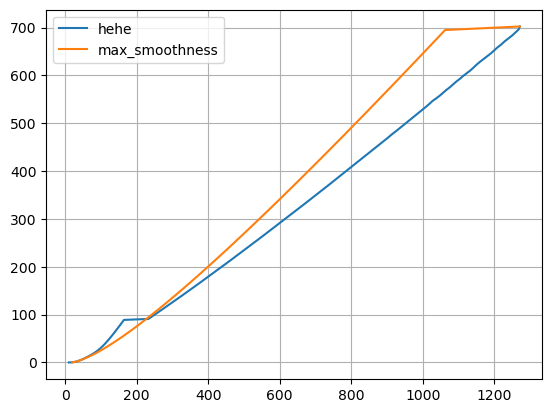

In [38]:
plt.plot(cols_e, cols_p, label = 'hehe')
plt.plot(eos[0][2], eos[0][0][:-1], label = "max_smoothness")
#plt.xlim(0,1300)
#plt.ylim(0,500)
plt.legend()
plt.grid()
plt.show() 

In [52]:
min_distance_points[0]

(3962.736, 7024.08)